In [3]:
!pip install lxml -q
import pandas as pd

df = pd.read_html('ispu_jakarta.xls')[0]
print("Baris x Kolom:", df.shape)
print("\nKolom:", df.columns.tolist())
df.head()


Baris x Kolom: (3501, 13)

Kolom: ['periode_data', 'bulan', 'tanggal', 'stasiun', 'pm_sepuluh', 'pm_duakomalima', 'sulfur_dioksida', 'karbon_monoksida', 'ozon', 'nitrogen_dioksida', 'max', 'parameter_pencemar_kritis', 'kategori']


,periode_data,bulan,tanggal,stasiun,pm_sepuluh,pm_duakomalima,sulfur_dioksida,karbon_monoksida,ozon,nitrogen_dioksida,max,parameter_pencemar_kritis,kategori
0,202401,1,21,DKI3 JAGAKARSA,51.0,65.0,45.0,9.0,8.0,79.0,79.0,NaN,SEDANG
1,202401,1,22,DKI3 JAGAKARSA,27.0,34.0,45.0,5.0,8.0,56.0,56.0,NaN,SEDANG
2,202401,1,23,DKI3 JAGAKARSA,NaN,52.0,46.0,6.0,9.0,51.0,52.0,PM25,SEDANG
3,202401,1,24,DKI3 JAGAKARSA,46.0,65.0,46.0,8.0,9.0,38.0,65.0,PM25,SEDANG
4,202401,1,25,DKI3 JAGAKARSA,37.0,55.0,47.0,7.0,11.0,28.0,55.0,PM25,SEDANG


In [4]:
# 1. Tipe data tiap kolom
df.info()

# 2. Missing values per kolom
print("\nMissing values:")
print(df.isnull().sum())

# 3. Daftar stasiun
print("\nStasiun:", df['stasiun'].unique())

# 4. Rentang periode data
print("\nPeriode:", df['periode_data'].min(), "s/d", df['periode_data'].max())

# 5. Kategori ISPU yang ada
print("\nKategori:", df['kategori'].unique())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3501 entries, 0 to 3500
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   periode_data               3501 non-null   int64  
 1   bulan                      3501 non-null   int64  
 2   tanggal                    3501 non-null   int64  
 3   stasiun                    3501 non-null   object 
 4   pm_sepuluh                 3237 non-null   float64
 5   pm_duakomalima             3440 non-null   float64
 6   sulfur_dioksida            3445 non-null   float64
 7   karbon_monoksida           3451 non-null   float64
 8   ozon                       3455 non-null   float64
 9   nitrogen_dioksida          3432 non-null   float64
 10  max                        3493 non-null   float64
 11  parameter_pencemar_kritis  3436 non-null   object 
 12  kategori                   3500 non-null   object 
dtypes: float64(7), int64(3), object(3)
memory usage:

In [9]:
# 1. Standarisasi nama stasiun
mapping = {
    'DKI1 BUNDERAN HI': 'DKI1 - Bundaran HI',
    'DKI1 BUNDARAN HOTEL INDONESIA (HI)': 'DKI1 - Bundaran HI',
    'DKI1 BUNDARAN HOTEL INDONESIA HI': 'DKI1 - Bundaran HI',
    'DKI2 KELAPA GADING': 'DKI2 - Kelapa Gading',
    'DKI3 JAGAKARSA': 'DKI3 - Jagakarsa',
    'DKI4 LUBANG BUAYA': 'DKI4 - Lubang Buaya',
    'DKI5 KEBON JERUK': 'DKI5 - Kebon Jeruk',
    'DKI5 KEBON JERUK JAKARTA BARAT': 'DKI5 - Kebon Jeruk',
}
df['stasiun'] = df['stasiun'].str.strip().map(mapping)

# 2. Kolom tanggal
df['date'] = pd.to_datetime(
    df['periode_data'].astype(str) + df['tanggal'].astype(str).str.zfill(2),
    format='%Y%m%d',
    errors='coerce'
)

# 3. Drop 1 baris tanggal invalid (202509-31: September cuma 30 hari)
print("Baris sebelum drop:", len(df))
df = df.dropna(subset=['date']).reset_index(drop=True)
print("Baris sesudah drop:", len(df))

# 4. Verifikasi
print("\n", df['stasiun'].value_counts())
print("\nRentang:", df['date'].min().date(), "s/d", df['date'].max().date())


Baris sebelum drop: 3501
Baris sesudah drop: 3500

 stasiun
DKI3 - Jagakarsa        700
DKI1 - Bundaran HI      700
DKI2 - Kelapa Gading    700
DKI4 - Lubang Buaya     700
DKI5 - Kebon Jeruk      700
Name: count, dtype: int64

Rentang: 2024-01-01 s/d 2025-11-30


=== 1. Hari TIDAK SEHAT per stasiun ===
                      sum  count   pct
stasiun                               
DKI5 - Kebon Jeruk    114    700  16.3
DKI4 - Lubang Buaya    80    700  11.4
DKI2 - Kelapa Gading   69    700   9.9
DKI1 - Bundaran HI     45    700   6.4
DKI3 - Jagakarsa       34    700   4.9

=== 2. Parameter kritis dominan ===
parameter_pencemar_kritis
PM25    2955
SO2      225
PM10     176
O3        52
NO2       27
CO         1
Name: count, dtype: int64

=== 3. % hari di atas SEDANG: 9.8% ===

=== 4. Rata-rata MAX per bulan ===
 bulan_angka
1     55.0
2     61.6
3     59.1
4     69.4
5     85.0
6     90.2
7     85.0
8     85.3
9     80.8
10    77.5
11    63.0
12    56.5
Name: max, dtype: float64


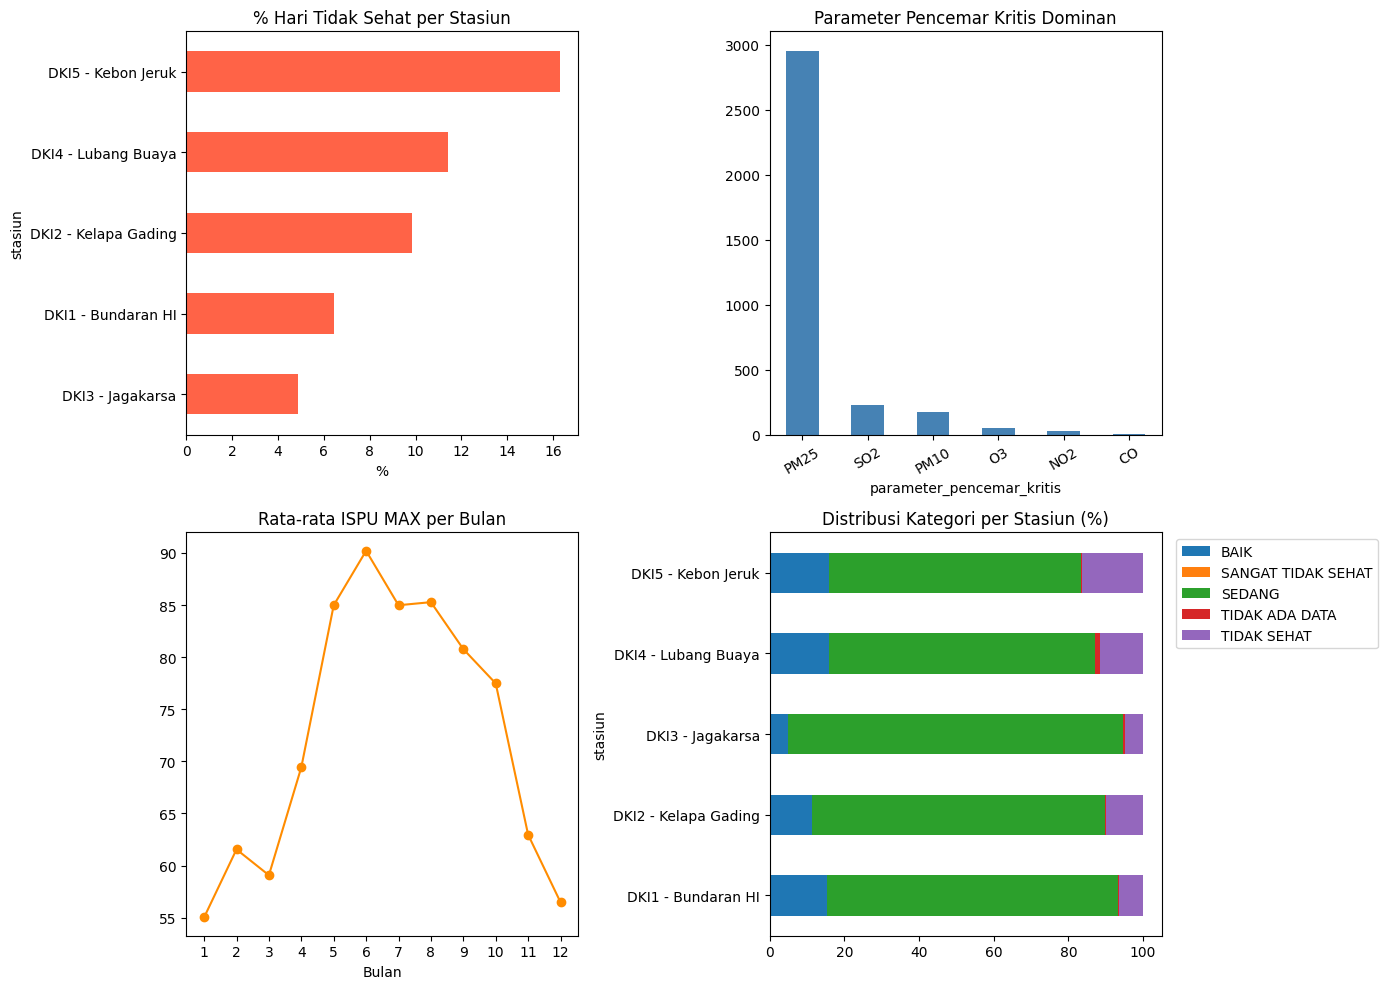

In [10]:
import matplotlib.pyplot as plt

# Flag hari tidak sehat
df['tidak_sehat'] = df['kategori'].isin(['TIDAK SEHAT', 'SANGAT TIDAK SEHAT'])

# 1. Stasiun paling sering tidak sehat
print("=== 1. Hari TIDAK SEHAT per stasiun ===")
unhealthy = df.groupby('stasiun')['tidak_sehat'].agg(['sum', 'count'])
unhealthy['pct'] = unhealthy['sum'] / unhealthy['count'] * 100
print(unhealthy.sort_values('pct', ascending=False).round(1))

# 2. Parameter pencemar kritis dominan
print("\n=== 2. Parameter kritis dominan ===")
print(df['parameter_pencemar_kritis'].value_counts())

# 3. % hari di atas SEDANG
pct = df['tidak_sehat'].mean() * 100
print(f"\n=== 3. % hari di atas SEDANG: {pct:.1f}% ===")

# 4. Rata-rata MAX per bulan (pola musiman)
df['bulan_angka'] = df['date'].dt.month
monthly = df.groupby('bulan_angka')['max'].mean()
print("\n=== 4. Rata-rata MAX per bulan ===\n", monthly.round(1))

# --- 4 CHART ---
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].set_title('% Hari Tidak Sehat per Stasiun')
unhealthy['pct'].sort_values().plot.barh(ax=axes[0, 0], color='tomato')
axes[0, 0].set_xlabel('%')

axes[0, 1].set_title('Parameter Pencemar Kritis Dominan')
df['parameter_pencemar_kritis'].value_counts().plot.bar(ax=axes[0, 1], color='steelblue')
axes[0, 1].tick_params(axis='x', rotation=30)

axes[1, 0].set_title('Rata-rata ISPU MAX per Bulan')
monthly.plot(ax=axes[1, 0], marker='o', color='darkorange')
axes[1, 0].set_xlabel('Bulan'); axes[1, 0].set_xticks(range(1, 13))

axes[1, 1].set_title('Distribusi Kategori per Stasiun (%)')
pd.crosstab(df['stasiun'], df['kategori'], normalize='index').mul(100).plot.barh(
    stacked=True, ax=axes[1, 1])
axes[1, 1].legend(bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()


In [11]:
# Re-run cell chart tadi, tapi ganti plt.show() jadi:
plt.savefig('ispu_jakarta_eda.png', dpi=150, bbox_inches='tight')
print("Chart tersimpan!")


Chart tersimpan!


<Figure size 640x480 with 0 Axes>